# Sections 6 & 7 across 30 non-flaring holdout ARs — the 672 hr ensemble

`view_harp11930_ensemble_mean_672hr.ipynb` measured two things on **one** frame, with the
same ten 672 hr bootstrap members used here:

| | HARP 11930, `20241001_1200` |
|---|---|
| §6 boundary **uncertainty** (member scatter about the ensemble boundary) | 5.25 ± 1.89 px |
| §6 boundary **error** (ensemble boundary against truth) | 10.88 px |
| **error / uncertainty** | **2.07x** |
| §7 Brier | 0.1148 |
| §7 bias ($\bar p$ − observed) | −0.0603, under-confident |

Both are $n = 1$, and that frame is deliberately extreme — a 9–11 region complex whose
mask is 6x denser than anything the members trained on. The 2.07x and the under-confidence
could be properties of *that frame* rather than of the ensemble.

This notebook runs the identical measurements over
`holdout_ar_nonflaring_30_from_test.csv`: 30 test-era ARs in the 10,000–20,000 million km²
band, each with a NOAA region, at most one sub-C1.0 flare, nothing in progress at the peak
frame. 27 of the 30 are flare-free outright. Mid-sized and quiescent — the control the
large/flaring holdout needs.

**The question is not "what is the ensemble's boundary uncertainty".** It is whether the
two single-frame readings survive 30 frames, and how much of the spread is frame identity
rather than member disagreement.

## Three things to hold on to before reading any number

**1. Uncertainty is not error, and this notebook never merges them.** Member scatter
measures only what the bootstrap can see. All ten members share one training distribution,
so any bias common to all of them is invisible to the spread. The ground-truth row exists
to measure exactly that gap — and on HARP 11930 the gap was a factor of two.

**2. The truth masks are whole-disk.** `union_with_intersect` covers *every* AR in the
frame, not only the catalog's target HARP. "Non-flaring" therefore describes the target
AR, not the frame: a quiescent 15,000 Mkm² region can share its disk with something
larger and livelier. This is the main thing that could still confound the comparison
against the top-3 result, and it is why §1 reports each frame's own positive fraction
rather than assuming the cohort is sparse.

**3. One Surya patch is 16 px, and that is the model's resolution floor.** Boundary
agreement finer than that is agreement about something the decoder cannot resolve. Read
the *tail* and the *across-frame spread*, not the median.

Read-only: no torch, no GPU. Everything comes from the cache
`analyze_holdout_sections67.py` wrote. Run from `downstream_examples/ar_segmentation/`.

## Setup

In [1]:
import json
import os
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from scipy import stats

if "." not in sys.path:
    sys.path.insert(0, ".")
import ensemble_viz as ev  # palette + raster helpers, shared with the other viewers
import false_color as fcolor  # SURYA_PATCH_PX

ev.apply_rcparams()

INFER_ROOT = "/efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_nonflaring30"
CATALOG = "./assets/surya-bench-ar-segmentation/holdout_ar_nonflaring_30_from_test.csv"
SCALERS_PATH = "./assets/scalers.yaml"
# The single-frame notebook's own section-8 cache, read for its published numbers rather
# than retyped. Its Brier/bias are not in that file (section 8 stored only the boundary
# attrs), so those two are the values the regression run of the analysis script
# reproduced exactly against the notebook's printed output.
REF_CACHE = "/efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_top3/20241001_1200/ensemble_mean.nc"
REF_BRIER, REF_BIAS = 0.1148, -0.0603

PATCH_PX = fcolor.SURYA_PATCH_PX
MIN_N = 1000          # reliability floor, as in the single-frame notebook
TRAIN_TRUE_FRAC = 0.00643   # training-era validation positive fraction
CHANNEL = "aia94"

frames = pd.read_csv(os.path.join(INFER_ROOT, "metrics_frame.csv"))
members = pd.read_csv(os.path.join(INFER_ROOT, "metrics_member_frame.csv"))
bins = pd.read_csv(os.path.join(INFER_ROOT, "calibration_bins.csv"))
dhist = pd.read_csv(os.path.join(INFER_ROOT, "distance_hist.csv"))
catalog = pd.read_csv(CATALOG)
scalers = yaml.safe_load(open(SCALERS_PATH))

MEMBERS = sorted(members.member.unique())
N = len(MEMBERS)
NF = len(frames)

with xr.open_dataset(REF_CACHE, engine="h5netcdf") as ds:
    REF = dict(ds.attrs)

print(f"{NF} frames x {N} members = {len(members)} member-frame rows")
print(f"reference frame: {REF['frame']}  HARP {REF['harpnum']}  "
      f"UNC {float(REF['boundary_assd_px']):.2f} px  "
      f"ERR {float(REF['boundary_error_assd_px']):.2f} px  "
      f"ratio {float(REF['boundary_error_over_uncertainty']):.2f}x")

# Every downstream aggregate assumes a complete balanced design; a partial inference run
# would otherwise be averaged silently.
assert len(members) == NF * N, f"expected {NF * N} member-frame rows, got {len(members)}"
bad = frames[frames.mean_check_abs_diff > 1e-3]
print(f"frames failing the fp16 mean-is-a-mean check: {len(bad) if len(bad) else 'none'}")
empty = frames[frames.empty_boundary_members.fillna("").astype(str).str.strip().ne("")]
print(f"frames where some member predicted nothing:   {len(empty) if len(empty) else 'none'}")

30 frames x 10 members = 300 member-frame rows
reference frame: 20241001_1200  HARP 11930  UNC 5.25 px  ERR 10.88 px  ratio 2.07x
frames failing the fp16 mean-is-a-mean check: none
frames where some member predicted nothing:   none


## 1. The cohort

What was actually measured, and how it differs from the single extreme frame. The column
that matters most is **truth AR fraction**: if these frames are no sparser than HARP
11930's 3.87 %, the cohort is not the control it was built to be.

In [2]:
cohort = frames.merge(
    catalog[["harpnum", "area_km2_million", "duration_days", "position", "n_flares",
             "max_goes_class", "n_euv_events", "noaa_regions"]],
    on="harpnum", how="left",
).sort_values("truth_frac", ascending=False)

tbl = cohort[["harpnum", "frame", "area_km2_million", "n_flares", "n_euv_events",
              "truth_frac", "truth_density_vs_train", "soft_iou",
              "boundary_assd_px", "boundary_error_assd_px",
              "boundary_error_over_uncertainty", "brier", "bias"]].copy()
tbl.columns = ["HARP", "frame", "area Mkm2", "flares", "EUV", "truth frac",
               "x train", "IoU", "UNC px", "ERR px", "ratio", "Brier", "bias"]
print(tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print(f"\ntruth AR fraction: mean {frames.truth_frac.mean():.5f}  "
      f"median {frames.truth_frac.median():.5f}  "
      f"[{frames.truth_frac.min():.5f}, {frames.truth_frac.max():.5f}]")
print(f"  = {frames.truth_density_vs_train.mean():.1f}x the training-era validation "
      f"fraction ({TRAIN_TRUE_FRAC:.5f}) on average")
print(f"  HARP 11930 for comparison: {float(REF['truth_positive_fraction']):.5f} "
      f"({float(REF['truth_positive_fraction']) / TRAIN_TRUE_FRAC:.1f}x)")
print(f"\n{int((cohort.n_flares == 0).sum())} of {NF} ARs are flare-free; "
      f"{int((cohort.n_flares > 0).sum())} have exactly one sub-C1.0 flare")
print(f"soft-mean IoU across the cohort: {frames.soft_iou.mean():.4f} +/- "
      f"{frames.soft_iou.std(ddof=1):.4f}  "
      f"[{frames.soft_iou.min():.4f}, {frames.soft_iou.max():.4f}]")

 HARP         frame  area Mkm2  flares  EUV  truth frac  x train    IoU   UNC px  ERR px  ratio  Brier    bias
11510 20240713_1700 16170.0000       0    2      0.0375   5.8311 0.7518  10.7526 40.3887 3.7562 0.1107 -0.0069
10434 20231127_0400 10889.0000       0    4      0.0344   5.3545 0.7448   6.1794 10.9075 1.7651 0.1206 -0.0640
11726 20240819_1900 11126.0000       0    6      0.0338   5.2623 0.7832   6.1395  8.5530 1.3931 0.0942 -0.0664
11555 20240719_1500 16004.0000       0    8      0.0330   5.1342 0.7389   5.8365 10.6407 1.8231 0.1165 -0.0488
11309 20240602_1400 11052.0000       0    4      0.0326   5.0657 0.8060   4.6429  8.3967 1.8085 0.0873 -0.0729
10515 20231220_1700 14163.0000       0    2      0.0292   4.5353 0.7679   9.4566 13.5931 1.4374 0.1009 -0.0504
11553 20240720_1800 18823.0000       0    2      0.0291   4.5208 0.7249   8.3720 20.2305 2.4165 0.1232  0.0085
10641 20240114_2200 13540.0000       0    1      0.0262   4.0671 0.6582  10.8043 27.1295 2.5110 0.1392 -0.0385
1

## 2. §6 — how well located is the boundary, over 30 frames?

The single-frame table becomes a distribution. Three numbers carry it:

- **UNC** — mean ASSD of the ten members' own $p_m = 0.5$ boundaries about the
  ensemble-mean boundary. What the bootstrap thinks it knows.
- **ERR** — the same measurement against the ground-truth mask. How wrong it is.
- **ratio** — ERR / UNC. **1.0 would mean the spread is an honest error bar.**

Reported as mean ± *between-frame* sd. Two ways to pool the ratio, and they answer
different questions: the mean of the 30 per-frame ratios weights every AR equally, while
mean-ERR / mean-UNC is the cohort-level ratio. Both are given because a few frames with
tiny UNC can inflate the first.

In [3]:
def describe(series, fmt="{:.3f}"):
    v = pd.to_numeric(series, errors="coerce").dropna()
    return (f"{fmt.format(v.mean())} +/- {fmt.format(v.std(ddof=1))}   "
            f"median {fmt.format(v.median())}   "
            f"[{fmt.format(v.min())}, {fmt.format(v.max())}]")


print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("UNCERTAINTY  ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("  between-member sd (px)", "boundary_assd_sd_px", "{:.2f}"),
    ("  median (px)", "boundary_median_px", "{:.2f}"),
    ("  mean HD95 (px)", "boundary_hd95_px", "{:.1f}"),
    ("ERROR  ASSD (px)", "boundary_error_assd_px", "{:.2f}"),
    ("  median (px)", "boundary_error_median_px", "{:.2f}"),
    ("  HD95 (px)", "boundary_error_hd95_px", "{:.1f}"),
    ("ERROR / UNCERTAINTY", "boundary_error_over_uncertainty", "{:.2f}"),
    ("sigma_p on the boundary", "boundary_sigma_prob", "{:.4f}"),
]:
    print(f"{label:<34}{describe(frames[col], fmt)}")

UNC = frames.boundary_assd_px.mean()
ERR = frames.boundary_error_assd_px.mean()
ratio_mean = frames.boundary_error_over_uncertainty.mean()
ratio_pooled = ERR / UNC
ref_ratio = float(REF["boundary_error_over_uncertainty"])

print(f"\n--- the headline ---")
print(f"  mean of the {NF} per-frame ratios : {ratio_mean:.2f}x  "
      f"(sd {frames.boundary_error_over_uncertainty.std(ddof=1):.2f})")
print(f"  cohort ratio, mean ERR / mean UNC : {ratio_pooled:.2f}x")
print(f"  HARP 11930, single frame          : {ref_ratio:.2f}x")
n_over = int((frames.boundary_error_over_uncertainty > 1).sum())
print(f"\n  frames where error exceeds uncertainty: {n_over}/{NF}")
print(f"  frames where it exceeds 2x:             "
      f"{int((frames.boundary_error_over_uncertainty > 2).sum())}/{NF}")
print(f"\n  for scale, one Surya patch is {PATCH_PX} px "
      f"({PATCH_PX * frames.arcsec_per_px.mean():.1f} arcsec, "
      f"{PATCH_PX * frames.km_per_px.mean():,.0f} km at disk centre)")
print(f"  mean UNC in physical units: {UNC * frames.arcsec_per_px.mean():.2f} arcsec = "
      f"{(frames.boundary_assd_px * frames.km_per_px).mean():,.0f} km")
print(f"  mean ERR in physical units: {ERR * frames.arcsec_per_px.mean():.2f} arcsec = "
      f"{(frames.boundary_error_assd_px * frames.km_per_px).mean():,.0f} km")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
UNCERTAINTY  ASSD (px)            13.97 +/- 19.69   median 9.56   [3.39, 114.59]
  between-member sd (px)          12.89 +/- 31.89   median 5.62   [1.63, 178.24]
  median (px)                     1.46 +/- 0.38   median 1.41   [1.00, 2.53]
  mean HD95 (px)                  86.8 +/- 115.3   median 54.8   [14.5, 615.8]
ERROR  ASSD (px)                  24.96 +/- 18.81   median 19.91   [8.40, 99.75]
  median (px)                     5.53 +/- 5.18   median 4.18   [3.00, 32.00]
  HD95 (px)                       166.5 +/- 153.4   median 103.8   [27.7, 646.2]
ERROR / UNCERTAINTY               2.28 +/- 1.31   median 1.91   [0.33, 6.71]
sigma_p on the boundary           0.2376 +/- 0.0191   median 0.2339   [0.2096, 0.2896]

--- the headline ---
  mean of the 30 per-frame ratios : 2.28x  (sd 1.31)
  cohort ratio, mean ERR / mean UNC : 1.79x
  HARP

### Is any one member reliably tighter than the others?

On HARP 11930 boot07 was the tightest member (ASSD 2.84 px) and boot08 the loosest
(7.96 px). With one frame there is no way to tell a real property of a checkpoint from
the luck of a single draw. Thirty frames can.

**Kendall's $W$** is the concordance of the 30 per-frame rankings: 1.0 means every frame
orders the members identically, 0 means the orderings are unrelated. A high $W$ says
member identity is a real and transferable property; a low one says per-frame ranking is
noise and the single-frame "boot07 is best" reading was not generalizable.

In [4]:
per_member = members.groupby("member").agg(
    assd_mean=("assd_px", "mean"), assd_sd=("assd_px", "std"),
    assd_min=("assd_px", "min"), assd_max=("assd_px", "max"),
    median_px=("median_px", "mean"), hd95=("hd95_px", "mean"),
    iou=("iou", "mean"), val_iou=("val_iou", "first"), epoch=("epoch", "first"),
).sort_values("assd_mean")

wide = members.pivot(index="frame", columns="member", values="assd_px")[list(per_member.index)]
ranks = wide.rank(axis=1)                      # 1 = tightest, within each frame
per_member["mean_rank"] = ranks.mean()
per_member["rank_sd"] = ranks.std(ddof=1)

out = per_member[["epoch", "val_iou", "assd_mean", "assd_sd", "assd_min", "assd_max",
                  "median_px", "hd95", "iou", "mean_rank", "rank_sd"]].copy()
out.columns = ["ep", "val IoU", "ASSD px", "sd", "min", "max", "median", "HD95",
               "IoU", "rank", "rank sd"]
print(out.to_string(float_format=lambda x: f"{x:.3f}"))

chi2, p_fried = stats.friedmanchisquare(*[wide[m].values for m in wide.columns])
W = chi2 / (NF * (N - 1))                      # Kendall's W from the Friedman statistic
print(f"\nKendall's W over the {NF} per-frame rankings: {W:.3f}  "
      f"(Friedman chi2 {chi2:.1f}, p {p_fried:.2e})")
print("  W near 1 -> member identity transfers across frames; "
      "near 0 -> per-frame ranking is noise")

tightest, loosest = per_member.index[0], per_member.index[-1]
print(f"\ntightest overall: {tightest} ({per_member.assd_mean.iloc[0]:.2f} px), "
      f"loosest: {loosest} ({per_member.assd_mean.iloc[-1]:.2f} px)")
print(f"  how often is {tightest} the tightest member of its frame? "
      f"{int((ranks[tightest] == 1).sum())}/{NF}")
print(f"  how often is {loosest} the loosest?                  "
      f"{int((ranks[loosest] == N).sum())}/{NF}")
print(f"  on HARP 11930 the tightest was boot07 (2.84 px), the loosest boot08 (7.96 px)")

        ep  val IoU  ASSD px     sd   min     max  median    HD95   IoU  rank  rank sd
member                                                                                
boot07   3    0.610    5.644  3.125 2.156  15.567   1.171  25.564 0.700 3.633    2.251
boot03   2    0.617    5.854  3.127 2.222  14.782   1.409  27.347 0.680 3.733    2.348
boot04   1    0.631    6.075  4.276 2.838  24.659   1.887  25.455 0.695 3.533    2.240
boot05   2    0.634    8.344  8.297 1.139  35.868   1.158  43.358 0.692 4.233    2.932
boot01   2    0.604    8.950  9.647 2.432  53.586   1.232  30.150 0.677 4.633    2.646
boot10   2    0.570   10.830  8.693 2.087  39.385   1.489  67.847 0.689 5.933    2.406
boot09   1    0.562   13.751  9.530 3.810  45.742   1.830  68.208 0.650 7.400    2.568
boot02   1    0.561   22.215 52.143 1.862 295.607   1.417 149.636 0.678 7.000    2.084
boot06   1    0.609   26.758 67.349 3.791 374.798   2.273 204.113 0.689 6.800    2.340
boot08   0    0.518   31.237 78.339 2.937 4

### Variance decomposition — is the member spread an error bar, or is the frame?

A one-way random-effects split of the 300 per-member ASSD values, with frame as the
grouping factor:

$$\sigma^2_{\text{total}} = \sigma^2_{\text{between frames}} + \sigma^2_{\text{within frame (members)}}$$

The **intraclass correlation** $\text{ICC} = \sigma^2_b / (\sigma^2_b + \sigma^2_w)$ is the
fraction of all variation attributable to *which AR you are looking at*.

This is the statistic that decides how to read a bootstrap error bar. A high ICC means
the member spread quoted on any single frame is mostly telling you about that frame, and
the quantity does not transfer. A low ICC means members genuinely disagree by a
frame-independent amount — and the error bar means something, even if §2 shows it is
still the wrong *size*.

In [5]:
m_, k_ = N, NF                                  # members per frame, frames
grand = wide.values.mean()
frame_means = wide.mean(axis=1)

ms_between = m_ * ((frame_means - grand) ** 2).sum() / (k_ - 1)
ms_within = ((wide.values - frame_means.values[:, None]) ** 2).sum() / (k_ * (m_ - 1))
var_between = max((ms_between - ms_within) / m_, 0.0)   # a negative estimate means 0
var_within = ms_within
icc = var_between / (var_between + var_within)

print(f"one-way random effects on the {k_ * m_} member-frame ASSD values")
print(f"  grand mean                        {grand:.3f} px")
print(f"  MS between frames                 {ms_between:.3f}")
print(f"  MS within frames (members)        {ms_within:.3f}")
print(f"\n  sigma_between (frame identity)    {np.sqrt(var_between):.3f} px   "
      f"({100 * icc:.0f} % of variance)")
print(f"  sigma_within  (member spread)     {np.sqrt(var_within):.3f} px   "
      f"({100 * (1 - icc):.0f} % of variance)")
print(f"  ICC                               {icc:.3f}")
print(f"\n  between-frame sd of the frame means: {frame_means.std(ddof=1):.3f} px")
print(f"  mean within-frame sd across frames:  {wide.std(axis=1, ddof=1).mean():.3f} px")

one-way random effects on the 300 member-frame ASSD values
  grand mean                        13.966 px
  MS between frames                 3876.590
  MS within frames (members)        1149.541

  sigma_between (frame identity)    16.514 px   (19 % of variance)
  sigma_within  (member spread)     33.905 px   (81 % of variance)
  ICC                               0.192

  between-frame sd of the frame means: 19.689 px
  mean within-frame sd across frames:  12.891 px


### Method A vs Method B

$\sigma_r = \sigma_p / |\nabla \bar p|$ (A, the linearized level-set displacement) and the
empirical ASSD (B, the headline) rest on different assumptions, so **agreement between
them is the check that either is meaningful**. On HARP 11930 they agreed to 1 % on the
mean. **Across these 30 frames they do not** — the correlation below is indistinguishable
from zero, and A sits about a third under B while staying inside a narrow few-pixel band
whatever B does. That is the expected failure, not a surprising one: A is a *local*
linearization of the level-set displacement and structurally cannot see a detached island
or a whole region the ensemble missed, which is exactly what inflates B. **Read the 1 %
on one frame as a coincidence rather than a validation — B is the headline, and A should
not be quoted as a cross-check across frames.** The two assumptions A rests on are
measured per frame, not asserted:

- **within-patch range** — if $\bar p$ were flat inside a patch, the raw gradient would be
  meaningless and the field would have to be smoothed first. It is not flat (HARP 11930:
  0.590).
- **patch-seam bias** — the gradient is steeper on patch seams, which makes A run
  optimistic where the boundary sits on one. That is why B is the headline.

In [6]:
cmp = frames[["frame", "boundary_assd_px", "sigma_r_mean_px", "sigma_r_median_px",
              "sigma_r_p90_px", "within_patch_range", "seam_bias_ratio"]].copy()
cmp["rel_diff_pct"] = 100 * (cmp.sigma_r_mean_px - cmp.boundary_assd_px) / cmp.boundary_assd_px

print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("Method B  ASSD (px)", "boundary_assd_px", "{:.2f}"),
    ("Method A  sigma_r mean (px)", "sigma_r_mean_px", "{:.2f}"),
    ("Method A  sigma_r median (px)", "sigma_r_median_px", "{:.2f}"),
    ("Method A  sigma_r p90 (px)", "sigma_r_p90_px", "{:.1f}"),
    ("A - B, as % of B", "rel_diff_pct", "{:+.1f}"),
    ("within-patch range of p-bar", "within_patch_range", "{:.3f}"),
    ("patch-seam gradient bias (x)", "seam_bias_ratio", "{:.2f}"),
]:
    print(f"{label:<34}{describe(cmp[col], fmt)}")

r, p_r = stats.pearsonr(cmp.boundary_assd_px, cmp.sigma_r_mean_px)
print(f"\nA vs B across the {NF} frames: r = {r:.3f} (p {p_r:.2e})")
print(f"  frames where the two agree to within 20 %: "
      f"{int((cmp.rel_diff_pct.abs() <= 20).sum())}/{NF}")
print(f"  on HARP 11930 they agreed to 1 % on the mean")
print(f"\nis p-bar flat inside a patch anywhere? "
      f"min within-patch range {cmp.within_patch_range.min():.3f} "
      f"-> {'no, the raw gradient is a real slope everywhere' if cmp.within_patch_range.min() > 0.1 else 'YES on some frame -- check it'}")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Method B  ASSD (px)               13.97 +/- 19.69   median 9.56   [3.39, 114.59]
Method A  sigma_r mean (px)       6.06 +/- 1.33   median 5.63   [4.39, 9.34]
Method A  sigma_r median (px)     3.51 +/- 0.69   median 3.39   [2.61, 5.77]
Method A  sigma_r p90 (px)        12.1 +/- 3.0   median 11.0   [8.3, 20.1]
A - B, as % of B                  -35.1 +/- +26.3   median -35.5   [-95.0, +42.2]
within-patch range of p-bar       0.594 +/- 0.030   median 0.599   [0.518, 0.637]
patch-seam gradient bias (x)      1.39 +/- 0.06   median 1.39   [1.26, 1.49]

A vs B across the 30 frames: r = 0.053 (p 7.81e-01)
  frames where the two agree to within 20 %: 4/30
  on HARP 11930 they agreed to 1 % on the mean

is p-bar flat inside a patch anywhere? min within-patch range 0.518 -> no, the raw gradient is a real slope everywhere


### The same comparison as a chart

Members in blue with **between-frame** error bars, sorted by mean ASSD; each frame's own
ERR against truth in orange on the right-hand panel. The reference line is one Surya
patch — the resolution floor, below which "agreement" is agreement about something the
decoder cannot represent.

A dot plot, not a lollipop: position encodes the value and nothing encodes length, so the
axis is free to zoom to the data rather than spending itself on an empty 0–2 px range.

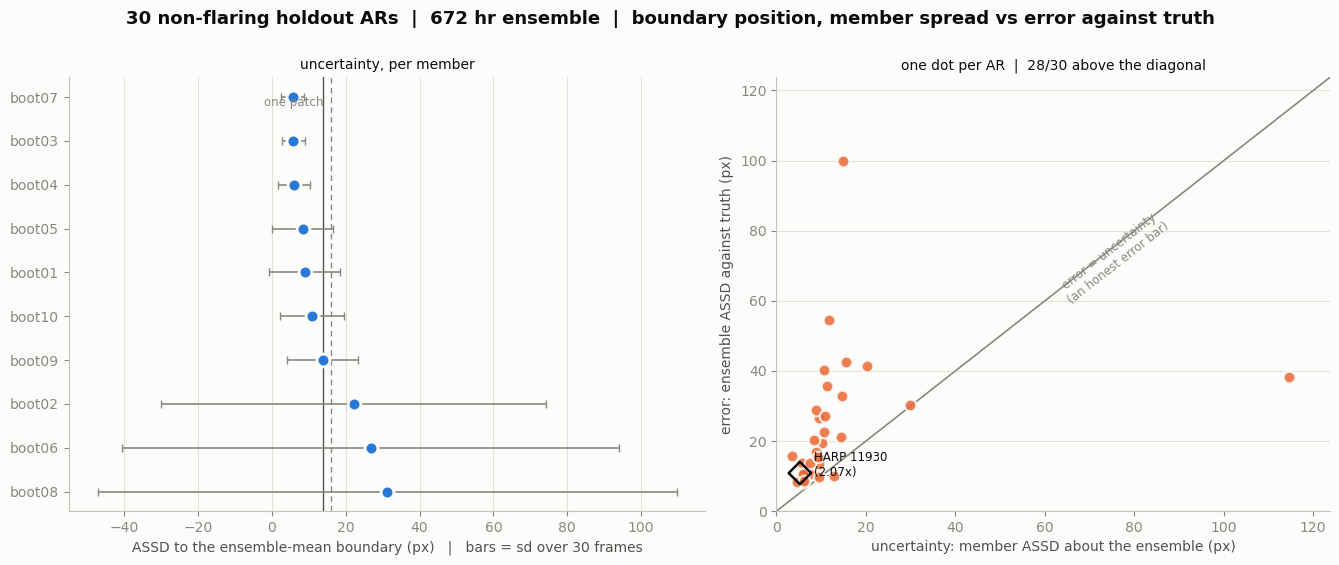

In [7]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13.5, 5.6),
                               gridspec_kw={"width_ratios": [1.15, 1]})
fig.suptitle(f"{NF} non-flaring holdout ARs  |  672 hr ensemble  |  "
             "boundary position, member spread vs error against truth",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

# ---- left: each member's ASSD about the ensemble boundary, averaged over frames
y = np.arange(N)
axl.errorbar(per_member.assd_mean, y, xerr=per_member.assd_sd, fmt="none",
             ecolor=ev.MUTED, elinewidth=1.2, capsize=3, zorder=2)
axl.scatter(per_member.assd_mean, y, s=85, color=ev.SERIES_1, zorder=3,
            edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
axl.axvline(UNC, color=ev.INK_2, lw=1.0, zorder=1)
axl.annotate(f"cohort mean {UNC:.2f} px", (UNC, N - 0.4), xytext=(5, 0),
             textcoords="offset points", fontsize=8.5, color=ev.INK_2)
axl.axvline(PATCH_PX, color=ev.MUTED, lw=1.0, ls=(0, (4, 3)), zorder=1)
axl.annotate("one patch", (PATCH_PX, 0.2), xytext=(-5, 0), textcoords="offset points",
             fontsize=8.5, color=ev.MUTED, ha="right")
axl.set_yticks(y)
axl.set_yticklabels(per_member.index)
axl.set_xlabel(f"ASSD to the ensemble-mean boundary (px)   |   bars = sd over {NF} frames")
axl.set_title("uncertainty, per member", fontsize=10, color=ev.INK)
axl.invert_yaxis()
ev.recessive(axl, grid_axis="x")

# ---- right: per-frame uncertainty against per-frame error. The diagonal is the claim
# that the spread is an honest error bar; everything above it is spread understating error.
lim = max(frames.boundary_assd_px.max(), frames.boundary_error_assd_px.max()) * 1.08
axr.plot([0, lim], [0, lim], color=ev.MUTED, lw=1.2, zorder=1)
axr.annotate("error = uncertainty\n(an honest error bar)", (lim * 0.62, lim * 0.62),
             xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8.5,
             color=ev.MUTED, rotation=38, rotation_mode="anchor")
axr.scatter(frames.boundary_assd_px, frames.boundary_error_assd_px, s=70,
            color=ev.SERIES_2, zorder=3, alpha=0.85,
            edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
axr.scatter([float(REF["boundary_assd_px"])], [float(REF["boundary_error_assd_px"])],
            s=130, marker="D", facecolors="none", edgecolors=ev.INK, linewidths=1.8,
            zorder=4)
axr.annotate(f"HARP 11930\n({ref_ratio:.2f}x)",
             (float(REF["boundary_assd_px"]), float(REF["boundary_error_assd_px"])),
             xytext=(10, -2), textcoords="offset points", fontsize=8.5, color=ev.INK)
axr.set_xlim(0, lim)
axr.set_ylim(0, lim)
axr.set_xlabel("uncertainty: member ASSD about the ensemble (px)")
axr.set_ylabel("error: ensemble ASSD against truth (px)")
axr.set_title(f"one dot per AR  |  {n_over}/{NF} above the diagonal",
              fontsize=10, color=ev.INK)
ev.recessive(axr)

plt.tight_layout()
plt.show()

### The whole distribution, not just its mean

Every boundary-to-boundary distance from all 30 frames, pooled. Read any point as *"this
fraction of boundary pixels lie within x px"*.

Members in grey, ground truth in orange — the **emphasis** form, because the story is the
one curve that sits apart. The gap between them **is** the gap between what the bootstrap
thinks it knows and how wrong it is.

Built from the per-frame histograms the analysis script accumulated (0.25 px bins out to
64 px, log-spaced beyond), so this is the exact pooled distribution over ~$10^8$
distances rather than a sample of it. One patch is an exact bin edge, so the
"within one patch" figures below are read off a boundary, not interpolated.

Log x-axis: the distances span three decades and a linear axis collapses the entire grey
band onto the left edge.

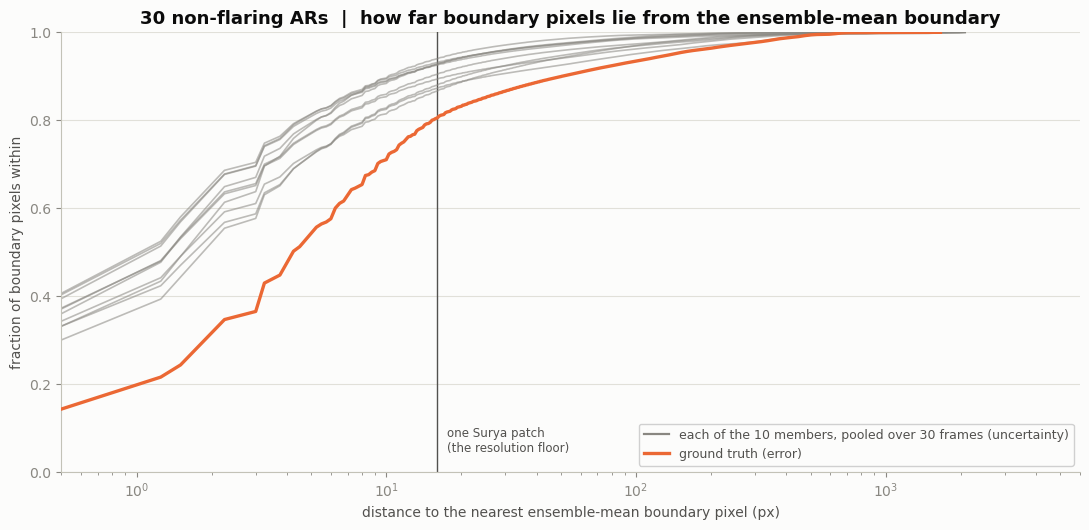

members (pooled)   within 1 patch (16 px):  90.5 %   within 2 patches:  94.3 %   median <=  1.50 px   n = 21,523,279
ground truth       within 1 patch (16 px):  80.5 %   within 2 patches:  87.1 %   median <=  4.25 px   n = 1,423,034

mean HD95 bounds the tail: 87 px for the members, 166 px for truth


In [8]:
def pooled_ecdf(df):
    "Summed counts -> (upper bin edge, cumulative fraction)."
    g = df.groupby("bin_hi", as_index=False)["count"].sum().sort_values("bin_hi")
    total = g["count"].sum()
    return g.bin_hi.values, np.cumsum(g["count"].values) / total, total


is_truth = dhist.series == "ground truth"
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.set_title(f"{NF} non-flaring ARs  |  how far boundary pixels lie from the "
             "ensemble-mean boundary", fontsize=13, fontweight="bold", color=ev.INK)

for member in MEMBERS:
    x, y, _ = pooled_ecdf(dhist[dhist.series == member])
    ax.plot(x, y, color=ev.MUTED, lw=1.2, alpha=0.55, zorder=2)
xt, yt, n_t = pooled_ecdf(dhist[is_truth])
ax.plot(xt, yt, color=ev.SERIES_2, lw=2.4, zorder=4)

ax.axvline(PATCH_PX, color=ev.INK_2, lw=1.0, zorder=1)
ax.annotate("one Surya patch\n(the resolution floor)", (PATCH_PX, 0.04), xytext=(7, 0),
            textcoords="offset points", fontsize=8.5, color=ev.INK_2, va="bottom")
ax.set_xscale("log")
ax.set_xlim(0.5, 6000)
ax.set_ylim(0, 1)
ax.set_xlabel("distance to the nearest ensemble-mean boundary pixel (px)")
ax.set_ylabel("fraction of boundary pixels within")
ev.recessive(ax)
ax.legend(handles=[
    plt.Line2D([], [], color=ev.MUTED, lw=1.6,
               label=f"each of the {N} members, pooled over {NF} frames (uncertainty)"),
    plt.Line2D([], [], color=ev.SERIES_2, lw=2.4, label="ground truth (error)")],
    loc="lower right", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
plt.tight_layout()
plt.show()


def within(df, limit):
    g = df.groupby("bin_hi", as_index=False)["count"].sum()
    return g.loc[g.bin_hi <= limit, "count"].sum() / g["count"].sum()


for label, sub in [("members (pooled)", dhist[~is_truth]), ("ground truth", dhist[is_truth])]:
    g = sub.groupby("bin_hi", as_index=False)["count"].sum().sort_values("bin_hi")
    tot = g["count"].sum()
    cum = np.cumsum(g["count"].values) / tot
    med = g.bin_hi.values[np.searchsorted(cum, 0.5)]
    print(f"{label:<18} within 1 patch ({PATCH_PX} px): {100 * within(sub, PATCH_PX):5.1f} %"
          f"   within 2 patches: {100 * within(sub, 2 * PATCH_PX):5.1f} %"
          f"   median <= {med:5.2f} px   n = {tot:,}")
print(f"\nmean HD95 bounds the tail: {frames.boundary_hd95_px.mean():.0f} px for the "
      f"members, {frames.boundary_error_hd95_px.mean():.0f} px for truth")

### Does the ratio track mask density?

The obvious confounder. HARP 11930's mask is 6x denser than the training-era validation
set, and if error-over-uncertainty simply grows with how much AR is in the frame, then the
2.07x was a statement about *that frame's* density and this cohort should sit somewhere
else on the same line.

Spearman rather than Pearson: the question is monotonicity, and both quantities have
long-tailed distributions across the cohort.

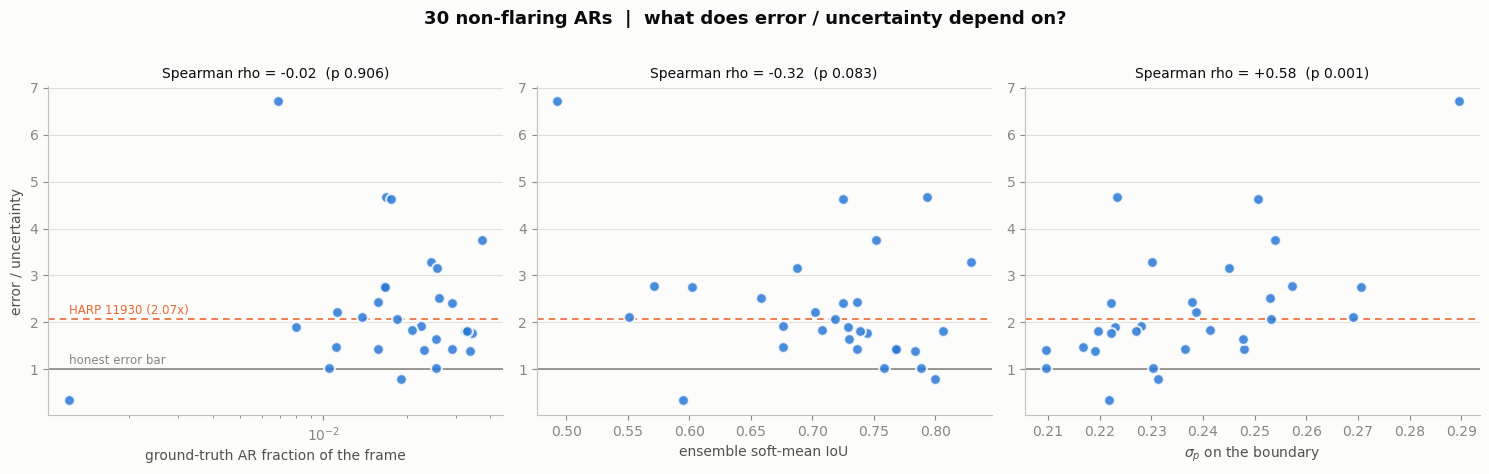

ratio vs truth AR fraction: Spearman rho -0.022 (p 0.906)
  -> no monotonic dependence on density in this band

The cohort spans 0.00121 - 0.03749 in positive fraction (31x), so this is a real test over a real range,
not a comparison of two points. HARP 11930 sits at 0.03870.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
fig.suptitle(f"{NF} non-flaring ARs  |  what does error / uncertainty depend on?",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax, (col, xlabel, logx) in zip(axes, [
    ("truth_frac", "ground-truth AR fraction of the frame", True),
    ("soft_iou", "ensemble soft-mean IoU", False),
    ("boundary_sigma_prob", r"$\sigma_p$ on the boundary", False),
]):
    rho, p_s = stats.spearmanr(frames[col], frames.boundary_error_over_uncertainty)
    ax.scatter(frames[col], frames.boundary_error_over_uncertainty, s=60,
               color=ev.SERIES_1, alpha=0.85, zorder=3,
               edgecolors=plt.rcParams["figure.facecolor"], linewidths=1.5)
    ax.axhline(1.0, color=ev.MUTED, lw=1.2, zorder=1)
    ax.axhline(ref_ratio, color=ev.SERIES_2, lw=1.2, ls=(0, (4, 3)), zorder=2)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_title(f"Spearman rho = {rho:+.2f}  (p {p_s:.3f})", fontsize=10, color=ev.INK)
    ev.recessive(ax)
axes[0].set_ylabel("error / uncertainty")
axes[0].annotate("honest error bar", (frames.truth_frac.min(), 1.0), xytext=(0, 4),
                 textcoords="offset points", fontsize=8.5, color=ev.MUTED)
axes[0].annotate(f"HARP 11930 ({ref_ratio:.2f}x)", (frames.truth_frac.min(), ref_ratio),
                 xytext=(0, 4), textcoords="offset points", fontsize=8.5, color=ev.SERIES_2)
plt.tight_layout()
plt.show()

rho, p_s = stats.spearmanr(frames.truth_frac, frames.boundary_error_over_uncertainty)
print(f"ratio vs truth AR fraction: Spearman rho {rho:+.3f} (p {p_s:.3f})")
print(f"  -> {'density explains some of the ratio' if p_s < 0.05 else 'no monotonic dependence on density in this band'}")
print(f"\nThe cohort spans {frames.truth_frac.min():.5f} - {frames.truth_frac.max():.5f} "
      f"in positive fraction ({frames.truth_frac.max() / frames.truth_frac.min():.0f}x), "
      f"so this is a real test over a real range,\nnot a comparison of two points. "
      f"HARP 11930 sits at {float(REF['truth_positive_fraction']):.5f}.")

## 3. §7 — Calibration, over 30 frames

Bin pixels by $\bar p$ and compare against the observed ground-truth frequency. On the
diagonal is perfect; **below is over-confident, above is under-confident**.

**A different axis from §2, and the two must not be merged.** §2 asked whether the member
spread is an honest error bar on the boundary's *position*. This asks whether the value
$\bar p$ is an honest frequency for a pixel's *class*. On HARP 11930 one was
over-confident and the other under-confident at the same time.

**Restricted to pixels where at least one member fired**, as in the single-frame notebook:
the $k = 0$ population is ~95 % of each frame and would set the curve's left end on its
own. Its own AR content is reported separately, because it is where the ensemble's misses
hide.

The pooled curve sums the raw per-frame bin accumulators ($n$, $n_{\text{true}}$,
$\sum \bar p$), so it is the exact curve over all 30 frames' pixels — not an average of
30 per-frame curves, which would weight a sparse frame the same as a dense one.

In [10]:
pooled = bins.groupby(["bin_lo", "bin_hi"], as_index=False)[["n", "n_true", "sum_p"]].sum()
pooled["mean_p"] = pooled.sum_p / pooled.n
pooled["observed"] = pooled.n_true / pooled.n
pooled["reliable"] = pooled.n >= MIN_N

show = pooled.assign(
    bin=lambda d: d.bin_lo.map("{:.1f}".format) + "-" + d.bin_hi.map("{:.1f}".format)
)[["bin", "n", "n_true", "mean_p", "observed", "reliable"]]
print(show.to_string(index=False, float_format=lambda x: f"{x:.4f}", na_rep="-"))

n_tot = int(pooled.n.sum())
mean_p = float(pooled.sum_p.sum() / n_tot)
observed = float(pooled.n_true.sum() / n_tot)
ok = pooled.reliable & pooled.n.gt(0)
w = pooled.n[ok] / pooled.n[ok].sum()
ece = float((w * (pooled.observed[ok] - pooled.mean_p[ok]).abs()).sum())

# Exact pooled Brier: the n-weighted mean of the per-frame Briers, each computed over that
# frame's own pixels. Equals the Brier over the union, which is why it is not re-derived
# from the bins (binning p would blur it).
brier_pooled = float((frames.brier * frames.n_binned).sum() / frames.n_binned.sum())

# Murphy decomposition, on the binned approximation. reliability - resolution +
# uncertainty recovers the *binned* Brier; the gap against the exact figure above is the
# within-bin variation of p-bar that binning discards, and is reported rather than hidden.
o_bar = observed
unc_term = o_bar * (1 - o_bar)
rel_term = float((pooled.n * (pooled.mean_p - pooled.observed) ** 2).sum() / n_tot)
res_term = float((pooled.n * (pooled.observed - o_bar) ** 2).sum() / n_tot)

print(f"\npooled over {n_tot:,} pixels where >=1 member fired "
      f"({100 * n_tot / (NF * 4096 * 4096):.2f} % of the {NF} frames)")
print(f"  mean p-bar {mean_p:.4f}   observed AR frequency {observed:.4f}   "
      f"bias {mean_p - observed:+.4f}")
print(f"  Brier (exact, n-weighted over frames) {brier_pooled:.4f}")
print(f"  ECE, weighted |observed - p-bar| over reliable bins: {ece:.4f}")
print(f"\n  Murphy decomposition of the binned Brier:")
print(f"    reliability (lower better)  {rel_term:.4f}")
print(f"    resolution  (higher better) {res_term:.4f}")
print(f"    uncertainty (base rate)     {unc_term:.4f}")
print(f"    rel - res + unc             {rel_term - res_term + unc_term:.4f}  "
      f"vs exact {brier_pooled:.4f}  "
      f"(gap {abs(rel_term - res_term + unc_term - brier_pooled):.4f} = within-bin spread)")
print(f"\n  HARP 11930 single frame: Brier {REF_BRIER:.4f}  bias {REF_BIAS:+.4f}")
thin = pooled.index[~pooled.reliable & pooled.n.gt(0)].tolist()
print(f"\n  pooled bins below the {MIN_N:,}-pixel floor: "
      + (f"{thin}" if thin else "none; every non-empty bin is a real measurement"))

print(f"\n--- what hides in k = 0 ---")
print(f"  excluded pixels: {int(frames.n_quiet.sum()):,} "
      f"({100 * frames.quiet_frac.mean():.2f} % of a frame on average)")
print(f"  their ground-truth AR frequency: "
      f"{describe(frames.quiet_true_frac, '{:.5f}')}")
print(f"  true AR pixels no member found:  "
      f"{describe(100 * frames.missed_ar_frac, '{:.1f}')} % of each frame's AR")
print(f"  (HARP 11930: 7.7 %)")

    bin       n  n_true  mean_p  observed  reliable
0.0-0.1  126663    6973  0.0845    0.0551      True
0.1-0.2  841530  134783  0.1555    0.1602      True
0.2-0.3 1175628  336787  0.2508    0.2865      True
0.3-0.4 1116274  448928  0.3488    0.4022      True
0.4-0.5  975767  494730  0.4491    0.5070      True
0.5-0.6  902998  547445  0.5495    0.6063      True
0.6-0.7  899357  631096  0.6503    0.7017      True
0.7-0.8  948177  768017  0.7509    0.8100      True
0.8-0.9 1212435 1093089  0.8531    0.9016      True
0.9-1.0 5356318 5284994  0.9771    0.9867      True

pooled over 13,555,147 pixels where >=1 member fired (2.69 % of the 30 frames)
  mean p-bar 0.6879   observed AR frequency 0.7191   bias -0.0311
  Brier (exact, n-weighted over frames) 0.1189
  ECE, weighted |observed - p-bar| over reliable bins: 0.0317

  Murphy decomposition of the binned Brier:
    reliability (lower better)  0.0015
    resolution  (higher better) 0.0840
    uncertainty (base rate)     0.2020
    rel - r

### Is the direction of the miscalibration consistent?

The pooled curve can hide cancelling frames. If the sign of the bias is the same on
nearly every AR, under-confidence is a property of the ensemble. If it is mixed, the
HARP 11930 reading was frame-specific and the pooled number is an average of two
different behaviours.

In [11]:
print(f"{'':<34}{'mean +/- sd':>22}   median / range")
print("-" * 78)
for label, col, fmt in [
    ("Brier (per frame)", "brier", "{:.4f}"),
    ("bias (p-bar - observed)", "bias", "{:+.4f}"),
    ("ECE", "ece", "{:.4f}"),
    ("mean p-bar where >=1 fired", "mean_p", "{:.4f}"),
    ("observed AR freq where >=1 fired", "observed", "{:.4f}"),
]:
    print(f"{label:<34}{describe(frames[col], fmt)}")

n_under = int((frames.bias < 0).sum())
n_over_c = int((frames.bias > 0).sum())
print(f"\n  under-confident (bias < 0, observed exceeds p-bar): {n_under}/{NF}")
print(f"  over-confident  (bias > 0):                        {n_over_c}/{NF}")
t_stat, p_t = stats.wilcoxon(frames.bias)
print(f"\n  Wilcoxon signed-rank on the {NF} biases vs 0: p = {p_t:.2e}")
print(f"  -> the sign is {'consistent across the cohort' if p_t < 0.05 else 'not consistent'}; "
      f"HARP 11930 was under-confident at {REF_BIAS:+.4f}")
print(f"\n  Spearman, bias vs truth AR fraction: "
      f"rho {stats.spearmanr(frames.truth_frac, frames.bias)[0]:+.3f} "
      f"(p {stats.spearmanr(frames.truth_frac, frames.bias)[1]:.3f})")

                                             mean +/- sd   median / range
------------------------------------------------------------------------------
Brier (per frame)                 0.1230 +/- 0.0258   median 0.1168   [0.0810, 0.1788]
bias (p-bar - observed)           -0.0233 +/- +0.0595   median -0.0309   [-0.1011, +0.2258]
ECE                               0.0604 +/- 0.0358   median 0.0529   [0.0249, 0.2258]
mean p-bar where >=1 fired        0.6770 +/- 0.0742   median 0.6878   [0.4446, 0.7672]
observed AR freq where >=1 fired  0.7003 +/- 0.1079   median 0.7207   [0.3649, 0.8352]

  under-confident (bias < 0, observed exceeds p-bar): 23/30
  over-confident  (bias > 0):                        7/30

  Wilcoxon signed-rank on the 30 biases vs 0: p = 1.46e-03
  -> the sign is consistent across the cohort; HARP 11930 was under-confident at -0.0603

  Spearman, bias vs truth AR fraction: rho -0.227 (p 0.228)


### The pooled reliability curve

The 30 per-frame curves sit behind the pooled one in grey, so the spread is visible rather
than averaged away. Bin counts are in the lower panel on a log scale, **not** a second
y-axis: a bin holding $10^3$ pixels and one holding $10^7$ must not be drawn as equals,
and two scales on one plot would invent a relationship between frequency and count that
is not there.

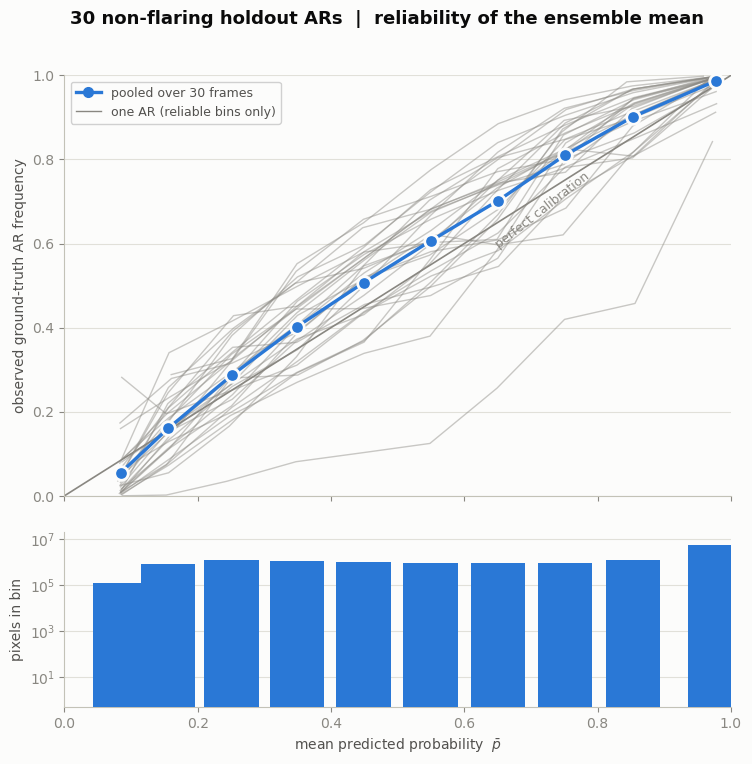

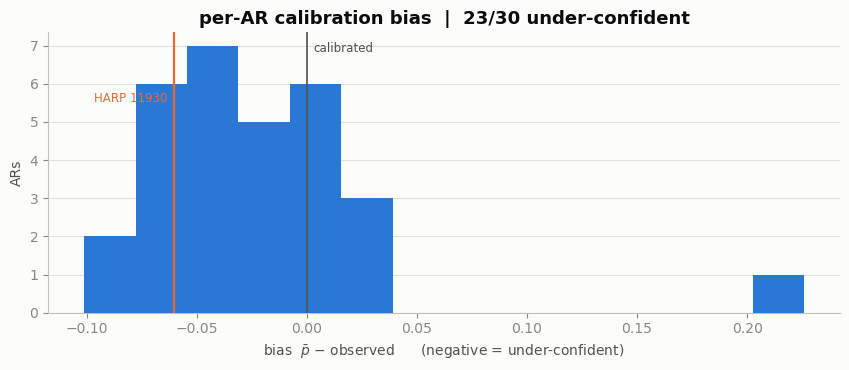

In [12]:
fig, (ax, axc) = plt.subplots(2, 1, figsize=(8.6, 8.2), sharex=True,
                              gridspec_kw={"height_ratios": [2.4, 1], "hspace": 0.12})
fig.suptitle(f"{NF} non-flaring holdout ARs  |  reliability of the ensemble mean",
             fontsize=13, fontweight="bold", color=ev.INK, y=0.96)

ax.plot([0, 1], [0, 1], color=ev.MUTED, lw=1.2, zorder=2)
ax.annotate("perfect calibration", (0.72, 0.72), xytext=(0, -14),
            textcoords="offset points", ha="center", fontsize=9, color=ev.MUTED,
            rotation=38, rotation_mode="anchor")

# Per-frame curves first, restricted to each frame's own reliable bins.
for frame, g in bins.groupby("frame"):
    g = g[g.n >= MIN_N]
    if len(g) > 1:
        ax.plot(g.sum_p / g.n, g.n_true / g.n, color=ev.MUTED, lw=1.0, alpha=0.45, zorder=3)

ax.plot(pooled.mean_p[ok], pooled.observed[ok], color=ev.SERIES_1, lw=2.4, zorder=5)
ax.scatter(pooled.mean_p[ok], pooled.observed[ok], s=95, color=ev.SERIES_1, zorder=6,
           edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
thin_mask = (~pooled.reliable) & pooled.n.gt(0)
if thin_mask.any():
    ax.scatter(pooled.mean_p[thin_mask], pooled.observed[thin_mask], s=95,
               facecolors="none", edgecolors=ev.SERIES_1, linewidths=2, zorder=6)
ax.set_ylabel("observed ground-truth AR frequency")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(handles=[
    plt.Line2D([], [], color=ev.SERIES_1, lw=2.4, marker="o", ms=7,
               label=f"pooled over {NF} frames"),
    plt.Line2D([], [], color=ev.MUTED, lw=1.0, label="one AR (reliable bins only)")],
    loc="upper left", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ev.recessive(ax)

axc.set_yscale("log")
nonempty = pooled.n > 0
axc.bar(pooled.mean_p[nonempty], pooled.n[nonempty], width=0.082, color=ev.SERIES_1,
        bottom=0.5, zorder=3)
axc.set_ylim(0.5, float(pooled.n.max()) * 4)
if thin_mask.any():
    axc.axhline(MIN_N, color=ev.MUTED, lw=1.0, zorder=4)
    axc.annotate(f"{MIN_N:,} px reliability floor", (0.02, MIN_N), xytext=(0, 5),
                 textcoords="offset points", fontsize=8.5, color=ev.MUTED, zorder=5)
axc.set_xlabel(r"mean predicted probability  $\bar p$")
axc.set_ylabel("pixels in bin")
ev.recessive(axc)
plt.show()

fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.set_title(f"per-AR calibration bias  |  {n_under}/{NF} under-confident",
             fontsize=13, fontweight="bold", color=ev.INK)
ax.hist(frames.bias, bins=14, color=ev.SERIES_1, zorder=3)
ax.axvline(0, color=ev.INK_2, lw=1.2, zorder=4)
ax.annotate("calibrated", (0, ax.get_ylim()[1] * 0.93), xytext=(5, 0),
            textcoords="offset points", fontsize=8.5, color=ev.INK_2)
ax.axvline(REF_BIAS, color=ev.SERIES_2, lw=1.6, zorder=4)
ax.annotate("HARP 11930", (REF_BIAS, ax.get_ylim()[1] * 0.75), xytext=(-5, 0),
            textcoords="offset points", fontsize=8.5, color=ev.SERIES_2, ha="right")
ax.set_xlabel(r"bias  $\bar p$ − observed      (negative = under-confident)")
ax.set_ylabel("ARs")
ev.recessive(ax)
plt.tight_layout()
plt.show()

## 4. Three exemplars

The aggregate needs something concrete under it. The AR with the **lowest**, the
**median** and the **highest** error-over-uncertainty, each with the $\sigma_r$ map on its
own most-contested window — the same panel §6 of the single-frame notebook draws.

$\sigma_r$ is recomputed here from the cached $\bar p$ and $\sigma_p$ rather than stored:
it costs a second and would have added 67 MB per frame to the cache.

Drawn only on the transition band $0.1 < \bar p < 0.9$. Outside it the ratio
$\sigma_p / |\nabla \bar p|$ divides a near-zero numerator by a near-zero denominator —
numerical noise with no boundary to be the uncertainty *of*. Values are clipped at one
patch rather than rescaled, so the colour means the same thing on all three panels.

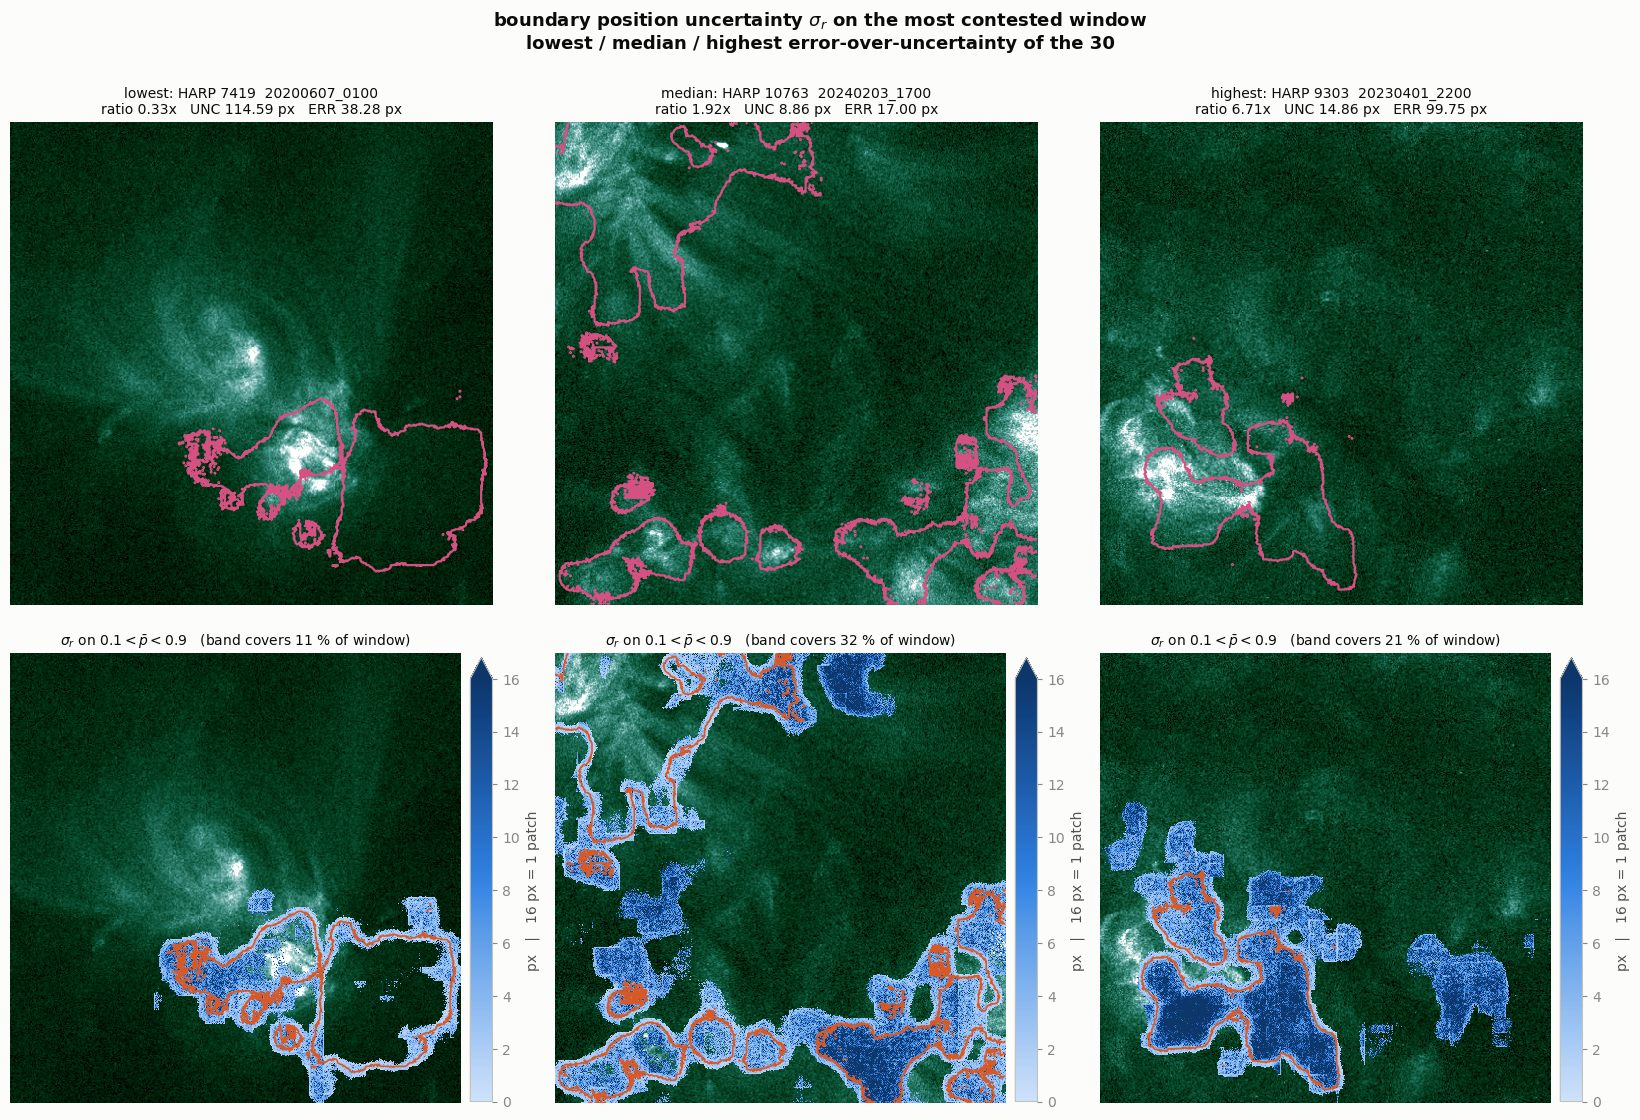

             HARP           frame   ratio   UNC px   ERR px     IoU  truth frac   Brier     bias
lowest       7419   20200607_0100    0.33   114.59    38.28  0.5947     0.00121  0.1643  +0.2258
median      10763   20240203_1700    1.92     8.86    17.00  0.6759     0.02260  0.1448  -0.0678
highest      9303   20230401_2200    6.71    14.86    99.75  0.4927     0.00687  0.1694  +0.0139


In [13]:
ordered = frames.sort_values("boundary_error_over_uncertainty").reset_index(drop=True)
picks = [("lowest", ordered.iloc[0]), ("median", ordered.iloc[NF // 2]),
         ("highest", ordered.iloc[-1])]


def load_channel(frame_dir, channel):
    "One channel in display units: undoes the standardization only, as infer_file does."
    with xr.open_dataset(os.path.join(frame_dir, "channels.nc"), engine="h5netcdf") as ds:
        normalized = ds[channel].values.astype(np.float32)
    s = scalers[channel]
    return normalized * (s["std"] + s["epsilon"]) + s["mean"]


fig, axes = plt.subplots(2, 3, figsize=(16.5, 11.4))
fig.suptitle(r"boundary position uncertainty $\sigma_r$ on the most contested window"
             "\nlowest / median / highest error-over-uncertainty of the 30",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.0)

for col, (tag, row) in enumerate(picks):
    frame_dir = os.path.join(INFER_ROOT, row.frame)
    with xr.open_dataset(os.path.join(frame_dir, "ensemble_mean.nc"),
                         engine="h5netcdf") as ds:
        p_mean = ds.ar_probability_mean.values
        p_sd = ds.ar_probability_sd.values
    gy, gx = np.gradient(p_mean)
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_r = (p_sd / np.hypot(gy, gx)).astype(np.float32)
    del gy, gx

    y0, x0, y1, x1 = int(row.win_y0), int(row.win_x0), int(row.win_y1), int(row.win_x1)
    img = load_channel(frame_dir, CHANNEL)[y0:y1, x0:x1]
    vmin, vmax = ev.channel_clim(CHANNEL, img)
    sub_soft = (p_mean > 0.5)[y0:y1, x0:x1]
    sub_pm = p_mean[y0:y1, x0:x1]
    sub_sigma = sigma_r[y0:y1, x0:x1]
    band = (sub_pm > 0.1) & (sub_pm < 0.9) & np.isfinite(sub_sigma)
    del p_mean, p_sd, sigma_r

    for r in (0, 1):
        axes[r, col].imshow(img, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
                            interpolation="nearest")
        axes[r, col].axis("off")

    axes[0, col].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.MASK_FILL],
                         linewidths=1.6)
    axes[0, col].set_title(
        f"{tag}: HARP {int(row.harpnum)}  {row.frame}\n"
        f"ratio {row.boundary_error_over_uncertainty:.2f}x   "
        f"UNC {row.boundary_assd_px:.2f} px   ERR {row.boundary_error_assd_px:.2f} px",
        fontsize=10, color=ev.INK)

    im = axes[1, col].imshow(np.ma.masked_where(~band, sub_sigma), cmap=ev.SEQ,
                             vmin=0, vmax=PATCH_PX, interpolation="nearest")
    axes[1, col].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.CONTOUR[0.5]],
                         linewidths=1.2)
    axes[1, col].set_title(
        r"$\sigma_r$ on $0.1 < \bar p < 0.9$"
        f"   (band covers {100 * band.mean():.0f} % of window)",
        fontsize=10, color=ev.INK)
    cb = fig.colorbar(im, ax=axes[1, col], fraction=0.046, pad=0.02, extend="max")
    cb.set_label(f"px   |   {PATCH_PX} px = 1 patch", color=ev.INK_2)

plt.tight_layout()
plt.show()

print(f"{'':<10}{'HARP':>7}{'frame':>16}{'ratio':>8}{'UNC px':>9}{'ERR px':>9}"
      f"{'IoU':>8}{'truth frac':>12}{'Brier':>8}{'bias':>9}")
for tag, row in picks:
    print(f"{tag:<10}{int(row.harpnum):>7}{row.frame:>16}"
          f"{row.boundary_error_over_uncertainty:>8.2f}{row.boundary_assd_px:>9.2f}"
          f"{row.boundary_error_assd_px:>9.2f}{row.soft_iou:>8.4f}"
          f"{row.truth_frac:>12.5f}{row.brier:>8.4f}{row.bias:>+9.4f}")

## What this cohort says

**1. The single-frame finding generalizes: the bootstrap spread is not an error bar.**
The mean of the 30 per-frame ratios is **2.28 ± 1.31** (median 1.91, range 0.33–6.71), and
HARP 11930's 2.07x sits essentially *at* the cohort median. 28 of 30 frames have error
exceeding uncertainty and 14 of 30 exceed 2x. The cohort-level mean-ERR / mean-UNC is
1.79x, lower than the mean of ratios only because one frame's 114 px UNC inflates the
denominator. Member scatter is a **lower bound on boundary error, roughly half of it** —
the same conclusion the single frame reached, now with 30 frames behind it.

**2. But the absolute scale is ~2.4x worse here, in the direction nobody predicted.**
UNC 13.97 px against 5.25, ERR 24.96 px against 10.88. The dense 9–11 region flaring
complex had a *better*-localized boundary than this mid-sized quiescent cohort: more
signal, a sharper boundary. In physical units UNC is 8.4″ ≈ 6,100 km and ERR 15.0″ ≈
10,885 km, against one Surya patch = 9.6″ ≈ 6,968 km — so the typical error is about **1.6
patches**, past the model's own resolution floor. Pooled over 21.5 M member distances and
1.42 M truth distances, **90.5 %** of member boundary pixels lie within one patch against
**80.5 %** for truth.

**3. The density confounder is ruled out.** ERR/UNC against truth positive fraction gives
Spearman $\rho = -0.022$ (p 0.91) over a **31x** density range, so the 2.07x was not an
artifact of HARP 11930's dense mask. Worth stating because this cohort is only 2x sparser
(0.0208, 3.2x the training-era validation fraction) than that frame (0.0387, 6.0x) —
assumption 5's whole-disk masks at work, which is why the test was necessary rather than
decorative.

**4. The member ranking is real on average and useless per frame.** Kendall's
$W = 0.331$ (Friedman p 2e-15) is significantly non-random yet far from concordant. The
extremes match the single frame — boot07 tightest at 5.64 px, boot08 loosest at 31.24 px —
but boot07 is its own frame's tightest on only **6/30** and boot08 its loosest on
**8/30**. The *mean* ordering transfers; the per-frame ordering is mostly noise, so the
single-frame "boot07 is the best member" reading was not transferable.
**boot02, boot06 and boot08 occasionally put a boundary 296–435 px from the ensemble** —
detection failures, not boundary wobble, and they are three of the four lowest validation
IoUs.

**5. Frame identity explains only a fifth of the spread.** $\sigma_{between} = 16.51$ px,
$\sigma_{within} = 33.91$ px, **ICC = 0.192**: 81 % of the variance in per-member ASSD is
members disagreeing with each other rather than which AR is being looked at. That is the
good news for treating the spread as a *frame-independent* quantity — but it is driven by
the heavy tail of those three members, not by uniform scatter, so the honest reading is
"the spread is dominated by a few bad checkpoints", not "members disagree by a stable
amount".

**6. A correction to the single-frame notebook: Method A does not cross-check Method B.**
$r = 0.053$ (p 0.78), 4/30 frames agree to within 20 %, and A runs **−35 %** below B.
A's own two assumptions hold on all 30 frames (within-patch range 0.594 ± 0.030, never
flat; seam bias 1.39 ± 0.06x), so this is not a broken measurement — it is A measuring a
different thing, a local linearized displacement that cannot see detached islands or
missed regions. **The 1 % agreement on HARP 11930 was a coincidence.** B stays the
headline; A must not be quoted as independent corroboration across frames.

**7. §7: $\bar p$ is consistently under-confident, and that direction is a property of the
ensemble.** Pooled over 13.56 M pixels where at least one member fired, mean $\bar p$
0.6879 against an observed 0.7191 — bias **−0.0311**, with **23 of 30** frames
under-confident (Wilcoxon p 1.5e-3). HARP 11930's −0.0603 is on the strong end but the
right sign. Brier 0.1189 pooled, ECE 0.0317, and a Murphy reliability term of **0.0015**:
the curve is genuinely close to the diagonal, it just sits above it. So the single-frame
recommendation survives — **thresholding below 0.5 is the right move, and it is not a
quirk of one frame**. The $k = 0$ population still hides **6.8 ± 2.3 %** of each frame's
true AR (HARP 11930: 7.7 %) across 489.8 M excluded pixels averaging 97.3 % of a frame;
no threshold reaches those pixels.

**Against the other two results.** The §9 672-vs-168 comparison found that 4x the training
data buys +0.038 IoU while leaving the error bar understating error ~2x; this cohort says
the same ratio holds across 30 *different* ARs, so that is a property of bootstrapping
this model rather than of either training regime or either frame. Nothing here
re-litigates the IoU numbers — these 30 frames were never scored against the 168 hr
members.

**What still limits all of it.**
- **The truth masks are whole-disk** (assumption 5). "Non-flaring" describes each
  catalog's *target* AR, not the frame, so some of the 24.96 px ERR is boundary error on
  neighbouring regions that may not be quiescent at all. §1's per-frame positive fractions
  are the available handle on this; a per-HARP-restricted mask is the clean fix and is not
  done here.
- **672 hr members only.** Every script is `--regime`-parameterized, so the 168 hr pass is
  a re-run with one flag.
- **One timestep per AR**, and all ten members share one training distribution. A bias
  common to all of them is invisible to UNC by construction — which is the whole reason
  the ERR column exists in this notebook.